![logo](https://github.com/HelmholtzAI-Consultants-Munich/XAI-Tutorials/blob/main/docs/source/_figures/Helmholtz-AI.png?raw=true)

# Model-Agnostic Interpretation with Permutation Feature Importance

In this notebook, we will demonstrate how to use the Permutation Feature Importance method and interpret its results.

--------


## Getting Started

### Setup Colab environment

If you installed the packages and requirements on your machine, you can skip this section and start from the import section.
Otherwise, you can follow and execute the tutorial on your browser. To start working on the notebook, click on the following button. This will open this page in the Colab environment, and you will be able to execute the code on your own.

<a href="https://colab.research.google.com/github/HelmholtzAI-Consultants-Munich/XAI-Tutorials/blob/main/xai-for-random-forest/Bio-1-Tutorial_PermutationFeatureImportance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Now that you opened the notebook in Colab, run the next cell. It fetches the tutorials and installs the requirements. Running the notebook locally, that cell does nothing: you already have the repository and the requirements.

**Note:** Google Colab may ask you to restart the runtime after installing the required packages. If prompted, restart the runtime before continuing with the notebook.

In [1]:
# On Google Colab: fetch the course and install the requirements.
# Running locally this cell does nothing, because you already have the repository and installed the requirements yourself.
try:
    import google.colab  
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    %cd /content
    !rm -rf XAI-Tutorials
    !git clone --depth 1 --branch main https://github.com/HelmholtzAI-Consultants-Munich/XAI-Tutorials.git
    %cd XAI-Tutorials
    !pip install -r requirements_xai-for-random-forest.txt
    %cd xai-for-random-forest


### Imports

Let's start with importing all required Python packages.

In [2]:
import sys
import pickle

import numpy as np

from sklearn.metrics import get_scorer, balanced_accuracy_score
from sklearn.inspection import permutation_importance

sys.path.append('./')
import utils

# assert reproducible random number generation
seed = 1
np.random.seed(seed)

--------------

## Introduction to Permutation Feature Importance

**We prepared a small [Introduction to Permutation Feature Importance](https://xai-tutorials.readthedocs.io/en/latest/_model_agnostic_xai/pfi.html) for you, to help you understand how this method works.**

*Note: we provide all references [here](https://xai-tutorials.readthedocs.io/en/latest/_model_agnostic_xai/pfi.html#references).*


<font color='green'>

#### Questionnaire:

1. What is achieved by permuting a feature’s values?

   A) The feature is removed from the dataset so that the model cannot use it.  
   B) The feature’s values are shuffled across samples, disrupting their associations with the target and other features while preserving the feature’s overall distribution.  
   C) The feature’s values are replaced with random numbers drawn from a different distribution.  
   D) The feature and target are shuffled together, preserving their relationship.  

2. Why do we shuffle individual features rather than the target when calculating PFI?

   A) Shuffling the target would require retraining the model.  
   B) Shuffling the target would change the number of samples in the dataset.  
   C) Shuffling the target would always improve the model’s performance.  
   D) Shuffling the target would disrupt its relationship with all features at once, rather than isolate the model’s reliance on one feature.  

3. Why do we shuffle a feature rather than remove it when calculating PFI?

   A) Shuffling preserves the input structure, allowing us to evaluate the same trained model. Removing a feature would generally require training a different model.  
   B) Shuffling ensures that every feature receives a positive importance value.  
   C) Removing a feature would also remove its corresponding target values.  
   D) Shuffling allows the model to learn how to compensate for the disrupted feature.  

4. What does a negative permutation importance value mean?

   A) The feature decreases the predicted target value.  
   B) The model cannot make predictions without the feature.  
   C) The model performs better after the feature’s values are shuffled.  
   D) The feature should always be removed immediately.  

</font>

<div style="color: grey; font-size: 0.85em;">

#### Your Answer:

1. What is achieved by permuting a feature’s values?

   ⚪ A) Permutation does not remove the feature. The column remains in the dataset, but its values are reassigned to different samples.  
   🟢 B) Permutation shuffles the existing values across samples. This disrupts their original associations with the target and other features while preserving the values and their frequencies. Some associations may remain by chance in an individual shuffle.  
   ⚪ C) Permutation uses the feature’s existing values rather than generating new random values.  
   ⚪ D) Only the selected feature is shuffled. The target and all other features remain unchanged.  

2. Why do we shuffle individual features rather than the target when calculating PFI?

   ⚪ A) Shuffling the target does not itself require retraining. The problem is that the resulting performance change would not isolate the importance of one feature.  
   ⚪ B) Shuffling changes the assignment of values to samples, not the number of samples.  
   ⚪ C) Shuffling the target does not systematically improve performance. It disrupts the alignment between the inputs and their correct target values.  
   🟢 D) Shuffling the target disrupts its alignment with all features simultaneously. The resulting performance change therefore cannot be attributed to one feature.  

3. Why do we shuffle a feature rather than remove it when calculating PFI?

   🟢 A) Shuffling keeps the input structure unchanged, so we can evaluate the original model without retraining. Removing a feature and retraining would instead measure how well a different model performs without that feature.  
   ⚪ B) PFI values can be positive, close to zero, or negative, depending on how performance changes after shuffling.  
   ⚪ C) Removing a feature removes an input column, not the corresponding target values.  
   ⚪ D) The model is not retrained during PFI, so it does not learn to compensate for the shuffled feature.  

4. What does a negative permutation importance value mean?

   ⚪ A) PFI measures changes in predictive performance, not whether a feature increases or decreases the predicted target value.  
   ⚪ B) Negative importance does not mean that predictions are impossible without the feature. It describes an improvement in performance after shuffling.  
   🟢 C) Negative importance means that the model performs better after the feature is shuffled. This may reflect random variation or patterns learned by the model that do not generalize well. If the result is consistent across repetitions, it may be worth evaluating a retrained model without the feature.  
   ⚪ D) A negative estimate alone is not sufficient reason to remove a feature. First check whether the result is stable, and validate whether removing the feature and retraining actually improves performance.  

</div>

--------

## Data and Model Loading: The Wisconsin Breast Cancer Dataset

In this notebook, we will work with the **Wisconsin Breast Cancer dataset**, containing 569 samples of 212 malignant and 357 benign tumors. Tumors are described by 30 numeric features computed from a digitized image taken of a breast mass (for more details please see the description [here](https://scikit-learn.org/stable/datasets/toy_dataset.html#breast-cancer-dataset)).

<center><img src="https://github.com/HelmholtzAI-Consultants-Munich/XAI-Tutorials/blob/main/docs/source/_figures/dataset_breastcancer.png?raw=true" width="700" /></center>

<font size=1> Source: [Link](https://www.kaggle.com/code/midouazerty/breast-cancer-prediction-99)

In the notebook [*Bio-0-Tutorial_RandomForest_Model_BreastCancer.ipynb*](./Bio-0-Tutorial_RandomForest_Model_BreastCancer.ipynb), we explain how to do the exploratory data analysis, preprocess the data and train a Random Forest model with the given data. The focus of this notebook is the interpretation of the previously trained model.

In [3]:
# Load the saved data splits and the already trained Random Forest
with open('../models/model_rf_breastcancer.pickle', 'rb') as handle:
    X_train, X_test, y_train, y_test, model_breastcancer = pickle.load(handle)

print(f'Model Performance on training data: {round(balanced_accuracy_score(y_train, model_breastcancer.predict(X_train))*100,2)} % balanced accuracy.')
print(f'Model Performance on test data: {round(balanced_accuracy_score(y_test, model_breastcancer.predict(X_test))*100,2)} % balanced accuracy.')

Model Performance on training data: 100.0 % balanced accuracy.
Model Performance on test data: 93.35 % balanced accuracy.


As we can see by the numbers above, our model performs well on the training set and also generalizes well to the independent test set.

**You should keep in mind that interpreting a low-performing model can lead to wrong conclusions.**

## Now, what does my model actually think is important in the data?

Now, let's use Permutation Feature Importance to get insights into the Random Forest Classification model we loaded above. We can use the scikit-learn implementation called `permutation_importance` to get the importance values for the features in our model. For measuring the performance drop when permuting a feature, we use the standard metric of our trained model, which is, in our case, the accuracy score. Using the same score enables us to evaluate the performance drop in relation to the baseline performance. We do 40 repetitions of permutation for each feature to get more reliable results.

*Note: this method is a **global** method, which means that it only provides explanations for the full dataset but not for individual examples.*

*Note: Features that are deemed of low importance for a bad model (low test score) could be very important for a good model. Therefore, it is always important to evaluate the predictive power of a model using a held-out set prior to computing importances. Permutation importance does not reflect the intrinsic predictive value of a feature by itself but how important this feature is for a particular model.*

In [4]:
# Convert the metric name into a scorer that permutation_importance can use.
scorer = get_scorer("accuracy")

In [5]:
# Evaluate the existing model without retraining it.
explanation_train = permutation_importance(
    model_breastcancer,
    X=X_train,
    y=y_train,
    n_repeats=40,           # Shuffle each feature 40 times to assess variability.
    random_state=seed,      # Make the random permutations reproducible.
    scoring=scorer
)

# Each importance is the original score minus the score after shuffling.
# The result contains all repetitions, their means, and their standard deviations.

# Attach feature names in the same order as the importance values.
explanation_train["feature"] = X_train.columns

We now plot bar plots to visualize the importance of each feature, computed as the mean across the 40 permutation repetitions.

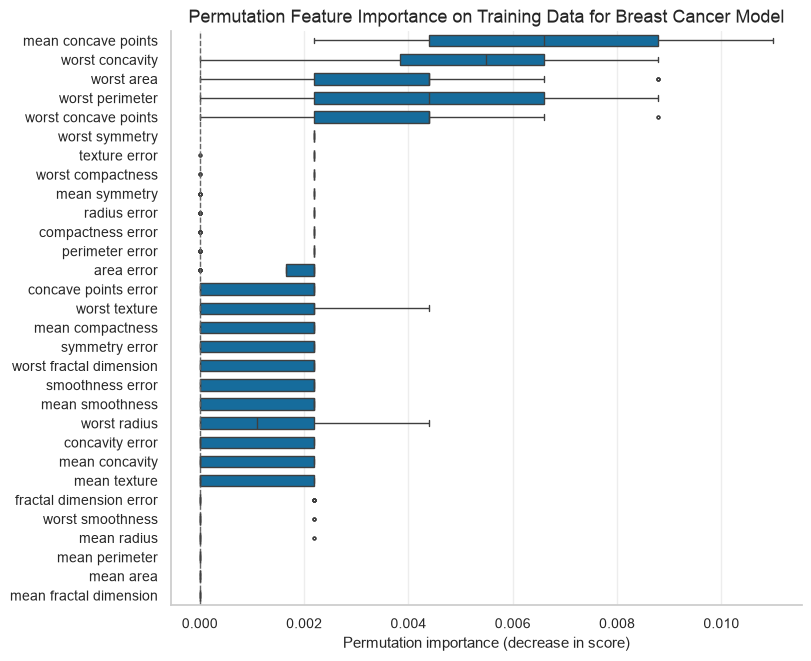

In [6]:
utils.plot_permutation_feature_importance(explanation_train, X_train, 'Permutation Feature Importance on Training Data for Breast Cancer Model')

<font color='green'>

#### Question: Does low importance mean we can remove a feature?

Suppose we add a second, almost identical measurement of `mean radius` to the Wisconsin Breast Cancer dataset. We train a Random Forest using both measurements to classify tumors as benign or malignant. The model performs well on unseen test data, but shuffling either radius measurement individually causes only a small decrease in accuracy. A colleague concludes: “Neither radius measurement is important, so we can safely remove both.”

Do you agree? Explain how both measurements could receive low permutation importance despite containing useful information. What would you expect if you shuffled both together, using the same row permutation? How would you test whether both measurements can actually be removed?

</font>

<div style="color: grey; font-size: 0.85em;">

#### Your Answer:

The two radius measurements contain overlapping information. If the trained model uses both as substitutes, shuffling one may have little effect because the other still provides useful information. Low individual importance therefore does not establish that both are unnecessary. Shuffling both measurements together preserves their relationship with each other but disrupts their associations with the target and the remaining features. If the model relies strongly on their shared information, we would expect a larger decrease in accuracy than when shuffling either measurement alone. This joint permutation measures the **existing model’s reliance on the pair**. To investigate whether both measurements can be removed, we would retrain a model without them and compare performance using the same validation procedure. The new model might learn to use other features, so its performance cannot be inferred directly from PFI.

</div>

---

### Dealing with Correlated Features

In the introduction video you already learned that applying permutation importance to datasets that contain correlated features can be problematic in various ways.
This is also emphasized in the [scikit-learn documentation](https://scikit-learn.org/stable/modules/permutation_importance.html#permutation-importance):

"*When two features are correlated and one of the features is permuted, the model will still have access to the feature through its correlated feature. This will result in a lower importance value for both features, where they might actually be important.*"

So, let's have a look at the amount of correlation we exhibit in our dataset.

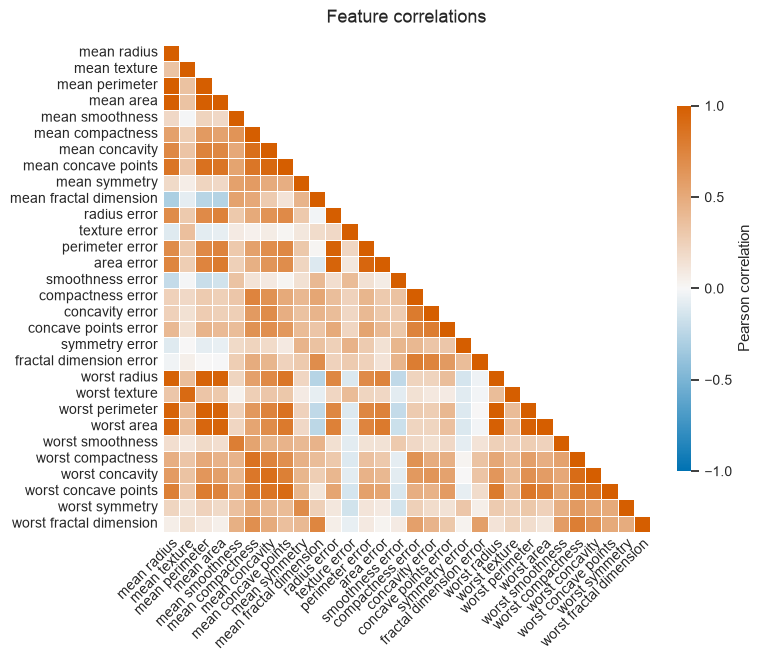

In [7]:
# Look for features that may contain overlapping information.
# Correlation describes relationships between inputs, not model reliance.
utils.plot_correlation_matrix(X_train, annot=False)

Looking at the correlation matrix above, we notice that we have a lot of correlation among features in our dataset. For instance, the *worst concave points* is highly correlated (correlation > 0.8) to eight other features in the dataset. To showcase the effect of correlation on the feature importance analysis, we will load a second Random Forest model that was trained on a selected set of uncorrelated features. 

In [8]:
with open('../models/model_rf_breastcancer_sel.pickle', 'rb') as handle:
    X_train_sel, X_test_sel, y_train_sel, y_test_sel, model_breastcancer_sel = pickle.load(handle)

print(f'Model Performance on training data: {round(balanced_accuracy_score(y_train_sel, model_breastcancer_sel.predict(X_train_sel))*100,2)} % balanced accuracy.')
print(f'Model Performance on test data: {round(balanced_accuracy_score(y_test_sel, model_breastcancer_sel.predict(X_test_sel))*100,2)} % balanced accuracy.')

Model Performance on training data: 98.01 % balanced accuracy.
Model Performance on test data: 90.58 % balanced accuracy.


Next, we compute the permutation feature importance for the Random Forest Classifier trained on the selected feature set.

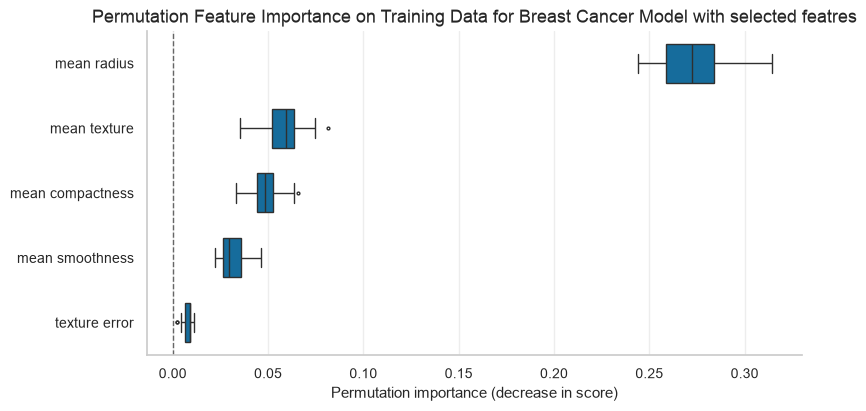

In [9]:
explanation_train_sel = permutation_importance(
    model_breastcancer_sel,
    X=X_train_sel,
    y=y_train_sel,
    n_repeats=40,
    random_state=seed,
    scoring=scorer
)

explanation_train_sel["feature"] = X_train_sel.columns

utils.plot_permutation_feature_importance(explanation_train_sel, X_train_sel, 'Permutation Feature Importance on Training Data for Breast Cancer Model with selected featres')

The plots above show how much influence feature correlation has on the permutation feature importances. For the model trained on the selected feature set, the most important feature leads to a mean decrease in accuracy of ~30%, which is in concordance with the observed model accuracy. In addition, the feature importance has a much higher stability as the variance of the feature importances across different permutations is much smaller. This illustrates why you have to be careful when using Permutation Feature Importance for models that were trained on datasets with high feature correlations!

We are not restricted to obtaining feature importances for the same dataset we used to train the model. Instead, we could use the same approach to identify the most important features in the test set.

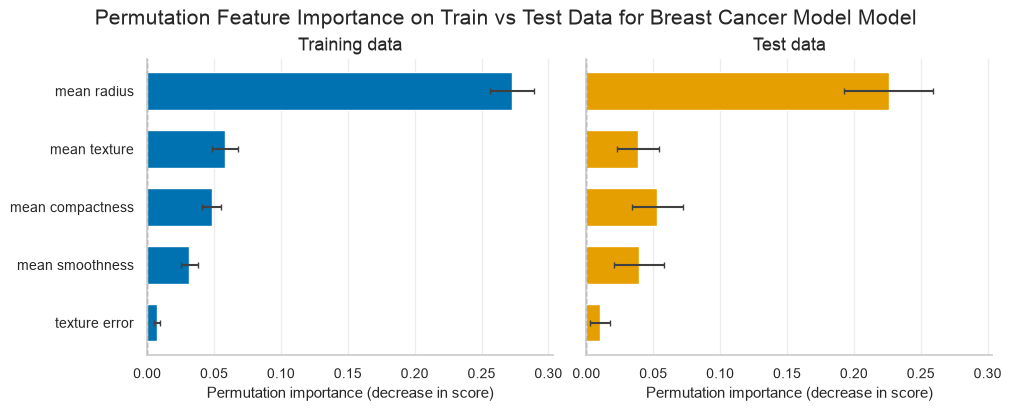

In [10]:
# Keep the model fixed, but evaluate feature reliance on unseen samples.
# Use the same metric and number of repetitions as for the training data.
explanation_test_sel = permutation_importance(
    model_breastcancer_sel,
    X=X_test_sel,
    y=y_test_sel,
    n_repeats=40,
    random_state=seed,
    scoring=scorer)

explanation_test_sel["feature"] = X_test_sel.columns

utils.plot_permutation_feature_importance_train_vs_test(explanation_train_sel, X_train_sel, explanation_test_sel, X_test_sel, 'Permutation Feature Importance on Train vs Test Data for Breast Cancer Model Model')

It seems that for both datasets, largely the same features are identified as important, which is reassuring.

*Note: this agreement of important features between training and testing datasets is not guaranteed. In such cases, it is not straightforward to decide on the "truly important" features for the model. A disagreement can be caused by high correlations in the dataset or even be an indicator that the model is not generalizable.*